# 과제 2 — ACT 정책 학습 및 실로봇 평가

**과제 내용**: 과제 1에서 수집한 데이터셋으로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가해 성공률을 측정한 뒤, 학습된 정책을 Huggingface Hub에 업로드한다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1과 같은 저장소, assignments 폴더)에 `assignment_2.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`를 추가할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [1]:
# 본인 정보
STUDENT_ID = "2020151003"
NAME = "고준협"
HF_USER = "go234"

TASK = "Pick up the cube and put it in the box."

TRAIN_DATASET = f"{HF_USER}/cube-box_20261013_041703"
POLICY_REPO   = f"{HF_USER}/act_pick_cube"
EVAL_DATASET  = f"{HF_USER}/rollout_eval_act_pick_cube"
WANDB_URL     = "https://forge.coreweave.com/wandb/jhk010529-/lerobot/runs/btn1oxr6"

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("정책 모델     :", f"https://huggingface.co/{POLICY_REPO}")
print("평가 데이터셋 :", f"https://huggingface.co/datasets/{EVAL_DATASET}")
print("wandb         :", WANDB_URL or "(미사용)")


학번/이름     : 2020151003 고준협
태스크        : Pick up the cube and put it in the box.
학습 데이터셋 : https://huggingface.co/datasets/go234/cube-box_20261013_041703
정책 모델     : https://huggingface.co/go234/act_pick_cube
평가 데이터셋 : https://huggingface.co/datasets/go234/rollout_eval_act_pick_cube
wandb         : https://forge.coreweave.com/wandb/jhk010529-/lerobot/runs/btn1oxr6


→ 과제 1의 데이터셋을 반드시 사용하지 않아도 됨.

In [2]:
# Hub 접근 확인 — 세 repo 모두 공개 상태이며 접근 가능해야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi(token=False)
checks = [(TRAIN_DATASET, "dataset"), (POLICY_REPO, "model"), (EVAL_DATASET, "dataset")]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개; 익명 접근)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")


OK   [dataset] go234/cube-box_20261013_041703  (파일 11개; 익명 접근)
OK   [model  ] go234/act_pick_cube  (파일 8개; 익명 접근)
OK   [dataset] go234/rollout_eval_act_pick_cube  (파일 8개; 익명 접근)


## 1. 학습 설정

### 1-1. 실행한 학습 명령어
```bash
lerobot-train \
  --dataset.repo_id=go234/cube-box_20261013_041703 \
  --policy.type=act \
  --policy.device=cuda \
  --policy.use_amp=true \
  --policy.repo_id=go234/act_pick_cube \
  --output_dir=outputs/train/act_pick_cube \
  --job_name=act_pick_cube \
  --batch_size=1 \
  --steps=100000 \
  --wandb.enable=true
```

### 1-2. 학습 환경
- GPU: Nvidia H200 (PyTorch 2.11.0+cu130, CUDA 사용 가능)
- 학습 step 수: 100,000
- 소요 시간: 약 52분 (W&B 시작 08:07, 학습 종료 로그 08:59 기준)
- 기본값에서 변경한 하이퍼파라미터와 이유: `batch_size=1`로 메모리 사용량을 낮추고, `policy.use_amp=true`로 CUDA 혼합 정밀도를 사용함.
- 결과: 100,000 step 학습 완료. 종료 후 Hugging Face 자동 업로드에서 401 인증 오류가 났으나, 체크포인트를 `go234/act_pick_cube`에 수동 업로드함. W&B run은 업로드 오류로 `Failed` 표시됨.


In [3]:
# 업로드된 정책의 설정 확인
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type, token=False)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

policy_cfg = load_json(POLICY_REPO, "config.json")
if policy_cfg:
    print("== 정책 설정 (config.json) ==")
    for k in ["type", "chunk_size", "n_action_steps", "n_obs_steps",
              "vision_backbone", "dim_model", "use_vae", "kl_weight", "optimizer_lr"]:
        if k in policy_cfg:
            print(f"{k:16}: {policy_cfg[k]}")

train_cfg = load_json(POLICY_REPO, "train_config.json")
if train_cfg:
    print("\n== 학습 설정 (train_config.json) ==")
    print("dataset   :", train_cfg.get("dataset", {}).get("repo_id"))
    for k in ["steps", "batch_size", "seed"]:
        if k in train_cfg:
            print(f"{k:10}: {train_cfg[k]}")

== 정책 설정 (config.json) ==
type            : act
chunk_size      : 100
n_action_steps  : 100
n_obs_steps     : 1
vision_backbone : resnet18
dim_model       : 512
use_vae         : True
kl_weight       : 10.0
optimizer_lr    : 1e-05

== 학습 설정 (train_config.json) ==
dataset   : go234/cube-box_20261013_041703
steps     : 100000
batch_size: 1
seed      : 1000


### 1-3. 학습 곡선
`[작성]` loss 곡선을 첨부한다. wandb 화면을 캡처해 저장소의 `images/loss_curve.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve.png)

In [ ]:
# (선택) wandb에서 loss를 CSV로 내보낸 경우 직접 그리기
# CSV에 step 열과 loss 열이 있다고 가정 — 열 이름은 본인 파일에 맞게 수정
import os
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "images/loss.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

### 2-1. 평가 명령어
실로봇에서 ACT 정책으로 10회 평가하고 평가 데이터셋을 공개 Hub 저장소에 업로드한다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=go234/act_pick_cube \
  --device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras="{cam1: {type: opencv, index_or_path: 4, width: 640, height: 480, fps: 25, fourcc: MJPG, backend: 200}, cam2: {type: opencv, index_or_path: 6, width: 640, height: 480, fps: 25, fourcc: MJPG, backend: 200}}" \
  --display_data=false \
  --dataset.repo_id=go234/rollout_eval_act_pick_cube \
  --dataset.private=false \
  --dataset.push_to_hub=true \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=20 \
  --dataset.reset_time_s=10
```

설치된 LeRobot 버전은 rollout용 데이터셋 이름이 `rollout_`으로 시작해야 한다고 검사한다. 과제 템플릿의 `eval_` 접두사 요구와 충돌하므로 현재는 `rollout_eval_act_pick_cube`를 사용한다. 실행 전 팔과 작업 공간을 확인한다. 리셋 구간에는 리더 팔이 연결되어 있지 않으므로 로봇 팔은 현재 자세를 유지한다. 에피소드 사이에는 물체를 초기 위치에 놓고 다음 회차를 시작한다.


In [4]:
# 평가 데이터셋 메타데이터 확인 — 에피소드 수가 10이어야 한다
info = load_json(EVAL_DATASET, "meta/info.json", repo_type="dataset")
if info:
    n_ep = info.get("total_episodes")
    print("평가 에피소드 수:", n_ep)
    print("총 프레임 수    :", info.get("total_frames"))
    print("fps             :", info.get("fps"))
    print("카메라          :", [k for k in info.get("features", {}) if k.startswith("observation.images")])
    print("\n에피소드 수 확인:", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

평가 에피소드 수: 10
총 프레임 수    : 5555
fps             : 30
카메라          : ['observation.images.cam1', 'observation.images.cam2']

에피소드 수 확인: 통과


### 2-2. 회차별 결과
`[작성]` 아래 코드 셀의 `results`를 실제 결과로 채운다. 실패한 경우 원인을 구체적으로 적는다.
(예: "큐브 위치를 놓침", "잡았으나 이동 중 떨어뜨림", "상자 가장자리에 걸림")

In [5]:
results = [
    # 실제 평가 결과: 사용자 확인 기준, 성공 5/10
    {"episode": 0, "success": False,  "note": "초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정"},
    {"episode": 1, "success": True,  "note": "큐브를 상자에 넣음"},
    {"episode": 2, "success": True,  "note": "큐브를 상자에 넣음"},
    {"episode": 3, "success": False,  "note": "초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정"},
    {"episode": 4, "success": True,  "note": "큐브를 상자에 넣음"},
    {"episode": 5, "success": False,  "note": "초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정"},
    {"episode": 6, "success": True,  "note": "큐브를 상자에 넣음"},
    {"episode": 7, "success": False,  "note": "초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정"},
    {"episode": 8, "success": False,  "note": "초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정"},
    {"episode": 9, "success": True,  "note": "큐브를 상자에 넣음"}
]

res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
print(f"성공률: {n_success}/{len(res_df)} = {n_success/len(res_df)*100:.0f}%")
res_df

성공률: 5/10 = 50%


 episode  success                                  note
       0    False 초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정
       1     True                            큐브를 상자에 넣음
       2     True                            큐브를 상자에 넣음
       3    False 초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정
       4     True                            큐브를 상자에 넣음
       5    False 초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정
       6     True                            큐브를 상자에 넣음
       7    False 초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정
       8    False 초기 환경과 상자 위치가 달라 목표 위치를 맞추지 못한 것으로 추정
       9     True                            큐브를 상자에 넣음

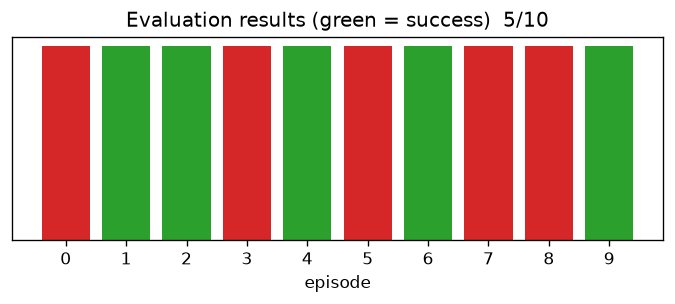

In [6]:
# 회차별 결과 시각화
colors = ["tab:green" if s else "tab:red" for s in res_df["success"]]
plt.figure(figsize=(7, 2.2))
plt.bar(res_df["episode"].astype(str), [1]*len(res_df), color=colors)
plt.yticks([]); plt.xlabel("episode")
plt.title(f"Evaluation results (green = success)  {n_success}/{len(res_df)}")
plt.show()

### 2-3. 평가 영상
`go234/rollout_eval_act_pick_cube`에서 대표 성공 영상은 에피소드 1, 실패 영상은 에피소드 0으로 선택했다. GIF는 cam2 전체 장면이며, 원본 영상은 LeRobot 뷰어에서 확인할 수 있다.

[성공 에피소드 1 원본 영상](https://huggingface.co/spaces/lerobot/visualize_dataset?path=%2Fgo234%2Frollout_eval_act_pick_cube%2Fepisode_1)

![성공 에피소드 1](images/success.gif)

[실패 에피소드 0 원본 영상](https://huggingface.co/spaces/lerobot/visualize_dataset?path=%2Fgo234%2Frollout_eval_act_pick_cube%2Fepisode_0)

![실패 에피소드 0](images/failure.gif)

## 3. 고찰

**3-1. 실패 원인 분석** — 실패는 0, 3, 5, 7, 8번 에피소드에서 발생했다. 제가 관찰한 공통 요인은 초기 환경이 일정하지 않고 상자 위치가 회차마다 달랐던 점이다. 이 위치 편차 때문에 정책이 학습 때 본 물체와 상자 사이의 관계를 평가 중에 재현하지 못했을 가능성이 있다.

**3-2. 데이터와 성능의 관계** — 시연 데이터에서 초기 배치와 상자 위치가 제한된 범위에 머물렀다면, 정책은 다양한 배치에 일반화하기 어려웠을 수 있다. 이번 평가에서 위치 변화와 함께 성공률이 5/10으로 나온 점은 학습 데이터의 배치 다양성이 성능에 영향을 주었을 가능성을 시사한다. 물체와 상자의 상대 위치를 더 폭넓게 포함한 시연이 있었다면 위치 변화에 더 잘 대응했을 것으로 생각한다.

**3-3. 개선 아이디어** — 먼저 매 회차의 큐브와 상자 시작 위치를 고정하고, 같은 조건에서 평가해 정책 성능을 비교하겠다. 다음 학습에서는 상자와 큐브의 상대 위치를 여러 가지로 바꾼 성공 시연을 추가하고, 각 배치가 균형 있게 포함되도록 데이터를 수집하겠다. 이후 위치별 성공률도 따로 기록해 어떤 배치에서 실패하는지 확인하겠다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [7]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype, token=False); return True
    except Exception:
        return False

check_items = {
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "정책 모델 업로드됨 (config.json)": file_ok(POLICY_REPO, "config.json", "model"),
    "정책 가중치 업로드됨 (model.safetensors)": file_ok(POLICY_REPO, "model.safetensors", "model"),
    "평가 데이터셋 에피소드 10개": bool(info) and info.get("total_episodes") == 10,
    "회차별 결과 10개 입력": len(results) == 10,
    "실패 회차에 원인 기재": all(r["note"].strip() for r in results if not r["success"]),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] 학습 데이터셋 접근 가능 (public)
[통과] 정책 모델 업로드됨 (config.json)
[통과] 정책 가중치 업로드됨 (model.safetensors)
[통과] 평가 데이터셋 에피소드 10개
[통과] 회차별 결과 10개 입력
[통과] 실패 회차에 원인 기재

모두 통과
